In [1]:
import sys; print(sys.executable)

/Users/home/agri-hackathon/.venv/bin/python


In [2]:
import pandas as pd
yields = pd.read_csv("../data/corn_yield_de.csv", dtype={"County ANSI": str})
yields.head()

,Program,Year,Period,Week Ending,Geo Level,State,State ANSI,Ag District,Ag District Code,County,...,Zip Code,Region,watershed_code,Watershed,Commodity,Data Item,Domain,Domain Category,Value,CV (%)
0,SURVEY,2025,YEAR,NaN,COUNTY,DELAWARE,10,NaN,99,OTHER COUNTIES,...,NaN,NaN,0,NaN,CORN,"CORN, GRAIN, IRRIGATED - YIELD, MEASURED IN BU...",TOTAL,NOT SPECIFIED,218.3,NaN
1,SURVEY,2025,YEAR,NaN,COUNTY,DELAWARE,10,NaN,99,OTHER COUNTIES,...,NaN,NaN,0,NaN,CORN,"CORN, GRAIN, NON-IRRIGATED - YIELD, MEASURED I...",TOTAL,NOT SPECIFIED,186.7,NaN
2,SURVEY,2025,YEAR,NaN,COUNTY,DELAWARE,10,CENTRAL,50,KENT,...,NaN,NaN,0,NaN,CORN,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,195.7,1.8
3,SURVEY,2025,YEAR,NaN,COUNTY,DELAWARE,10,NORTHERN,20,NEW CASTLE,...,NaN,NaN,0,NaN,CORN,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,211.9,4.9
4,SURVEY,2025,YEAR,NaN,COUNTY,DELAWARE,10,SOUTHERN,80,SUSSEX,...,NaN,NaN,0,NaN,CORN,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,184.9,1.4


In [8]:
import requests

url = "https://usdmdataservices.unl.edu/api/CountyStatistics/GetDroughtSeverityStatisticsByAreaPercent"
frames = []
for fips in ["10001", "10003", "10005"]:
    r = requests.get(url, params={
        "aoi": fips,
        "startdate": "1/1/2015",
        "enddate": "10/15/2026",
        "statisticsType": 1,
    }, headers={"Accept": "application/json"})
    frames.append(pd.DataFrame(r.json()))

drought = pd.concat(frames, ignore_index=True)
drought.to_csv("../data/drought_de.csv", index=False)
print(drought.shape)
drought.head()

(1848, 13)


,mapDate,fips,county,state,none,d0,d1,d2,d3,d4,validStart,validEnd,statisticFormatID
0,2026-10-13T00:00:00,10001,Kent County,DE,21.18,78.82,23.93,0.0,0.0,0.0,2026-10-13T00:00:00,2026-10-19T23:59:59,1
1,2026-10-06T00:00:00,10001,Kent County,DE,21.20,78.80,23.93,0.0,0.0,0.0,2026-10-06T00:00:00,2026-10-12T23:59:59,1
2,2026-09-29T00:00:00,10001,Kent County,DE,19.09,80.91,23.93,0.0,0.0,0.0,2026-09-29T00:00:00,2026-10-05T23:59:59,1
3,2026-09-22T00:00:00,10001,Kent County,DE,0.03,99.97,88.24,0.0,0.0,0.0,2026-09-22T00:00:00,2026-09-28T23:59:59,1
4,2026-09-15T00:00:00,10001,Kent County,DE,0.03,99.97,88.24,0.0,0.0,0.0,2026-09-15T00:00:00,2026-09-21T23:59:59,1


In [4]:
yields = pd.read_csv("../data/corn_yield_de.csv", dtype={"County ANSI": str})

corn = yields[
    (yields["Data Item"] == "CORN, GRAIN - YIELD, MEASURED IN BU / ACRE")
    & (yields["County"] != "OTHER COUNTIES")
][["Year", "County", "County ANSI", "Value"]].copy()

corn["yield_bu_acre"] = pd.to_numeric(corn["Value"].astype(str).str.replace(",", ""), errors="coerce")
corn["fips"] = "10" + corn["County ANSI"]
corn = corn.dropna(subset=["yield_bu_acre"])[["Year", "fips", "County", "yield_bu_acre"]]
corn.sort_values(["County", "Year"])

,Year,fips,County,yield_bu_acre
75,2015,10001,KENT,196.8
66,2016,10001,KENT,181.8
61,2017,10001,KENT,190.3
56,2018,10001,KENT,149.9
47,2019,10001,KENT,154.4
42,2020,10001,KENT,169.0
35,2021,10001,KENT,188.5
24,2022,10001,KENT,177.7
14,2023,10001,KENT,194.5
9,2024,10001,KENT,179.6


In [10]:
drought["mapDate"] = pd.to_datetime(drought["mapDate"])
drought["fips"] = drought["fips"].astype(str)
drought["Year"] = drought["mapDate"].dt.year
drought["dsci"] = drought[["d0", "d1", "d2", "d3", "d4"]].sum(axis=1)

season = drought[drought["mapDate"].dt.month.between(5, 8)]
dyear = season.groupby(["fips", "Year"], as_index=False)["dsci"].mean()
dyear.head()


,fips,Year,dsci
0,10001,2015,0.000000
1,10001,2016,1.010556
2,10001,2017,0.616667
3,10001,2018,5.555556
4,10001,2019,0.000000


In [6]:
merged = corn.merge(dyear, on=["fips", "Year"])
merged.to_csv("../data/merged.csv", index=False)
print(merged.shape)
merged.sort_values(["County", "Year"])


(33, 5)


,Year,fips,County,yield_bu_acre,dsci
30,2015,10001,KENT,196.8,0.000000
27,2016,10001,KENT,181.8,1.010556
24,2017,10001,KENT,190.3,0.616667
21,2018,10001,KENT,149.9,5.555556
18,2019,10001,KENT,154.4,0.000000
15,2020,10001,KENT,169.0,2.978235
12,2021,10001,KENT,188.5,6.508333
9,2022,10001,KENT,177.7,7.006667
6,2023,10001,KENT,194.5,36.455556
3,2024,10001,KENT,179.6,50.017647


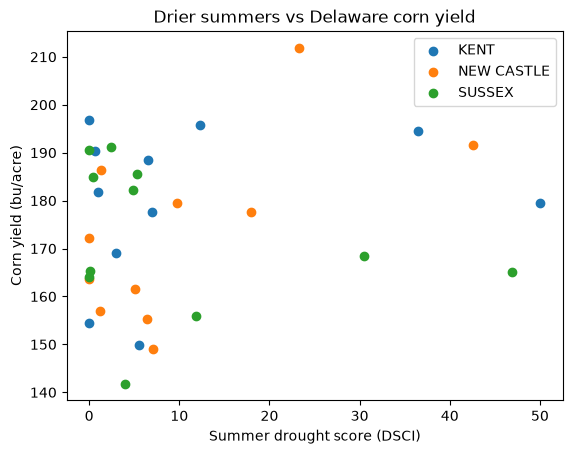

Correlation: 0.19


In [11]:
import matplotlib.pyplot as plt

for county, g in merged.groupby("County"):
    plt.scatter(g["dsci"], g["yield_bu_acre"], label=county)
plt.xlabel("Summer drought score (DSCI)")
plt.ylabel("Corn yield (bu/acre)")
plt.title("Drier summers vs Delaware corn yield")
plt.legend(); plt.show()

print("Correlation:", merged["dsci"].corr(merged["yield_bu_acre"]).round(2))

In [12]:
import numpy as np

def detrend(g):
    p = np.polyfit(g["Year"], g["yield_bu_acre"], 1)
    g = g.copy()
    g["yield_anom"] = g["yield_bu_acre"] - np.polyval(p, g["Year"])
    return g

m2 = merged.groupby("County", group_keys=False).apply(detrend)
print("Detrended correlation:", m2["dsci"].corr(m2["yield_anom"]).round(2))

Detrended correlation: 0.05


In [13]:
irr = yields[
    yields["Data Item"].str.contains("IRRIGATED - YIELD, MEASURED IN BU / ACRE")
    & (yields["County"] != "OTHER COUNTIES")
].copy()
irr["type"] = np.where(irr["Data Item"].str.contains("NON-IRRIGATED"), "non_irr", "irr")
irr["val"] = pd.to_numeric(irr["Value"].astype(str).str.replace(",", ""), errors="coerce")
irr["fips"] = "10" + irr["County ANSI"]

gap = irr.pivot_table(index=["Year", "fips", "County"], columns="type", values="val").dropna().reset_index()
gap["irr_gain"] = gap["irr"] - gap["non_irr"]
gap = gap.merge(dyear, on=["fips", "Year"])

print("Correlation (drought vs irrigation gain):", gap["dsci"].corr(gap["irr_gain"]).round(2))
gap.sort_values("dsci", ascending=False).head(10)

Correlation (drought vs irrigation gain): 0.24


,Year,fips,County,irr,non_irr,irr_gain,dsci
19,2024,10005,SUSSEX,204.0,105.1,98.9,46.934118
17,2023,10003,NEW CASTLE,235.3,186.0,49.3,42.588333
16,2023,10001,KENT,217.2,177.9,39.3,36.455556
15,2022,10005,SUSSEX,209.3,109.7,99.6,30.513333
11,2020,10005,SUSSEX,182.3,119.0,63.3,11.821176
13,2022,10001,KENT,216.7,144.8,71.9,7.006667
14,2022,10003,NEW CASTLE,250.5,141.5,109.0,6.460556
18,2023,10005,SUSSEX,211.1,148.6,62.5,5.281111
4,2016,10003,NEW CASTLE,222.5,153.6,68.9,5.065556
12,2021,10005,SUSSEX,207.5,147.0,60.5,4.908333


In [14]:
gap["summer"] = np.where(gap["dsci"] >= 10, "Dry (DSCI ≥ 10)", "Normal")
summary = gap.groupby(["County", "summer"])[["non_irr", "irr", "irr_gain"]].mean().round(0)
summary


non_irr    irr  irr_gain
County     summer                                   
KENT       Dry (DSCI ≥ 10)    178.0  217.0      39.0
           Normal             155.0  208.0      53.0
NEW CASTLE Dry (DSCI ≥ 10)    186.0  235.0      49.0
           Normal             158.0  225.0      67.0
SUSSEX     Dry (DSCI ≥ 10)    111.0  199.0      87.0
           Normal             139.0  204.0      65.0

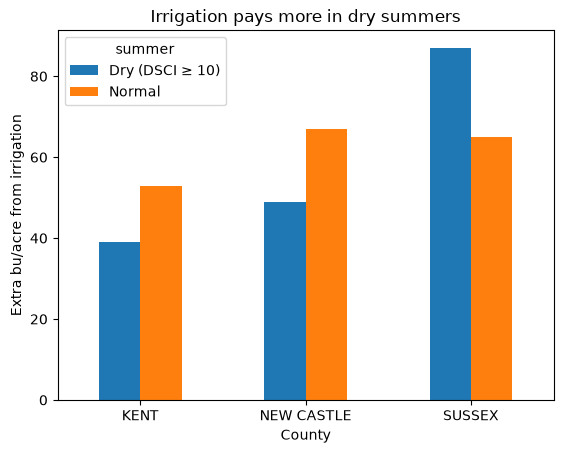

In [15]:
summary["irr_gain"].unstack().plot(kind="bar")
plt.ylabel("Extra bu/acre from irrigation")
plt.title("Irrigation pays more in dry summers")
plt.xticks(rotation=0); plt.show()

In [16]:
gap.to_csv("../data/irrigation_gap.csv", index=False)
print(gap.shape)

(21, 8)
